**Air raid forecasting**

In [1]:
import pandas as pd
import numpy as np

from interpretation import *
from experiments import *
from models import *
from evaluation import *
from data import *
from features import *

In [2]:
df_alerts = load_and_inspect_missing_data()
df_alerts_clean = remove_static_regions(df_alerts)
df_merged_oblasts = merge_oblast_intervals(df_alerts_clean)
df_merged_oblasts = remove_micro_alerts(df_merged_oblasts, min_minutes=2)

--- 1. Завантаження та Пропуски ---

[Весь період]
Кількість записів: 299275
Незавершені тривоги (NaN у 'finished_at'): 0 (0.00%)

[2026 рік]
Кількість записів: 85417
Незавершені тривоги (NaN у 'finished_at'): 0 (0.00%)
--- Видалення статичних регіонів ---
Видалені регіони: Luhanska oblast
Вилучено записів: 2
Залишилося записів для аналізу: 299273
--- 1. Злиття інтервалів на рівні областей ---
Кількість сирих записів: 299273
Кількість унікальних епізодів після злиття: 80287
--- Видалення мікротривог (< 2 хв) ---
Вилучено мікротривог: 278
Залишилося записів: 80009


In [3]:
df_panel1 = build_feature_panel(df_merged_oblasts, freq='15min', start_date='2024-07-01')
df_panel2 = build_feature_panel(df_merged_oblasts, freq='15min', start_date='2025-07-01')

file_path1 = 'df_features_final1.parquet'
df_panel1.to_parquet(file_path1, engine='pyarrow', index=False)
print(f"Пайплайн завершено. Фінальну матрицю 1 збережено у: {file_path1}")
print(f"Розмірність матриці: {df_panel1.shape}")

file_path2 = 'df_features_final2.parquet'
df_panel2.to_parquet(file_path2, engine='pyarrow', index=False)
print(f"Пайплайн завершено. Фінальну матрицю 2 збережено у: {file_path2}")
print(f"Розмірність матриці: {df_panel2.shape}")

--- Очищення часових зон (перехід до tz-naive) ---
--- Обрізка сирих даних з 2024-07-01 ---
Залишилось рядків (інтервалів): 39240
--- Побудова базової панелі (Точковий стан + інтервальний таргет) ---
Розмір панелі після обрізки: (1838220, 10)
--- Розрахунок ознак режиму (alert_pct та медіани) ---
--- Розрахунок просторових ознак ---
--- Розрахунок календарних ознак (Гармоніки) ---
--- Очищення часових зон (перехід до tz-naive) ---
--- Обрізка сирих даних з 2025-07-01 ---
Залишилось рядків (інтервалів): 23494
--- Побудова базової панелі (Точковий стан + інтервальний таргет) ---
Розмір панелі після обрізки: (995209, 10)
--- Розрахунок ознак режиму (alert_pct та медіани) ---
--- Розрахунок просторових ознак ---
--- Розрахунок календарних ознак (Гармоніки) ---
Пайплайн завершено. Фінальну матрицю 1 збережено у: df_features_final1.parquet
Розмірність матриці: (1838220, 22)
Пайплайн завершено. Фінальну матрицю 2 збережено у: df_features_final2.parquet
Розмірність матриці: (995209, 22)


In [4]:
grids1 = generate_downsampled_grids(df_panel1)
analyze_class_imbalance(grids1['15m'], "15 хв")
analyze_class_imbalance(grids1['30m'], "30 хв")
analyze_class_imbalance(grids1['60m'], "60 хв")

grids2 = generate_downsampled_grids(df_panel2)
analyze_class_imbalance(grids2['15m'], "15 хв")
analyze_class_imbalance(grids2['30m'], "30 хв")
analyze_class_imbalance(grids2['60m'], "60 хв")

--- Генерація даунсемпл-сіток ---
15 хв: 1838220 рядків
30 хв: 919118 рядків
60 хв: 459554 рядків

=== Аналіз дисбалансу: Сітка 15 хв ===
Глобально:
  0 (Спокій):  67.30%
  1 (Тривога): 32.70%

Якщо зараз НЕМАЄ тривоги (is_alert=0):
  Залишиться спокій (0): 85.75%
  Почнеться тривога (1): 14.25%

Якщо зараз Є тривога (is_alert=1):
  Закінчиться (0):   13.97%
  Продовжиться (1):  86.03%
----------------------------------------

=== Аналіз дисбалансу: Сітка 30 хв ===
Глобально:
  0 (Спокій):  67.27%
  1 (Тривога): 32.73%

Якщо зараз НЕМАЄ тривоги (is_alert=0):
  Залишиться спокій (0): 85.72%
  Почнеться тривога (1): 14.28%

Якщо зараз Є тривога (is_alert=1):
  Закінчиться (0):   14.01%
  Продовжиться (1):  85.99%
----------------------------------------

=== Аналіз дисбалансу: Сітка 60 хв ===
Глобально:
  0 (Спокій):  67.27%
  1 (Тривога): 32.73%

Якщо зараз НЕМАЄ тривоги (is_alert=0):
  Залишиться спокій (0): 85.70%
  Почнеться тривога (1): 14.30%

Якщо зараз Є тривога (is_alert=1):
  З

**Запуск моделей з довшим часом історії**


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 60 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2024-07-01 00:00:00  -->  2026-09-07 06:00:00
Train:         2024-07-31 00:00:00  -->  2026-05-07 02:00:00
Gap 1:         2 години
Validation:    2026-05-07 04:00:00  -->  2026-07-07 04:00:00
Gap 2:         2 години
Test:          2026-07-07 06:00:00  -->  2026-09-07 06:00:00

Розміри вибірок:
Train: 371592 рядків
Val:   35160 рядків
Test:  35736 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 0.9151 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35160 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35160 рядках): 0.0007 сек

📉 Log Loss:
   - Global: 5.1134
   - Peace (is_alert=0): 5.6225
   - Alert (is_alert=1): 3.9110


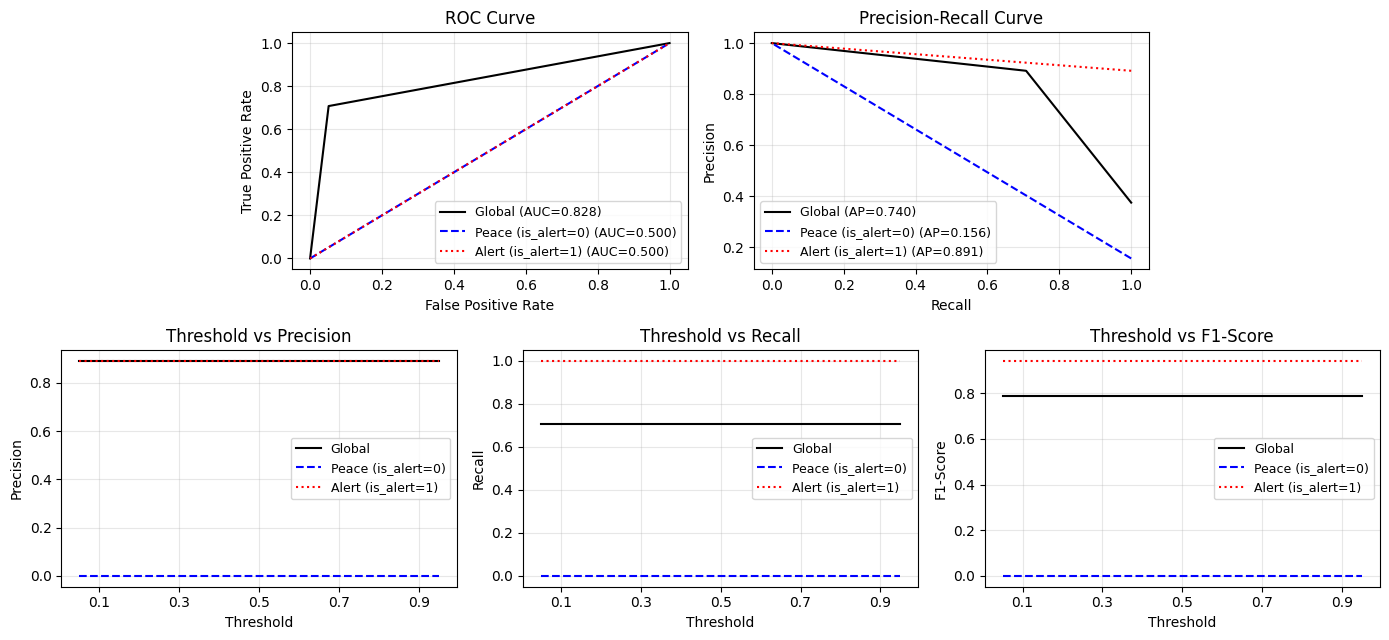


📊 Модель: Tree (1-step)
⏳ Час навчання: 0.92 сек
⏱ Час інференсу (на 35160 рядках): 0.0330 сек

📉 Log Loss:
   - Global: 0.3282
   - Peace (is_alert=0): 0.3504
   - Alert (is_alert=1): 0.2760


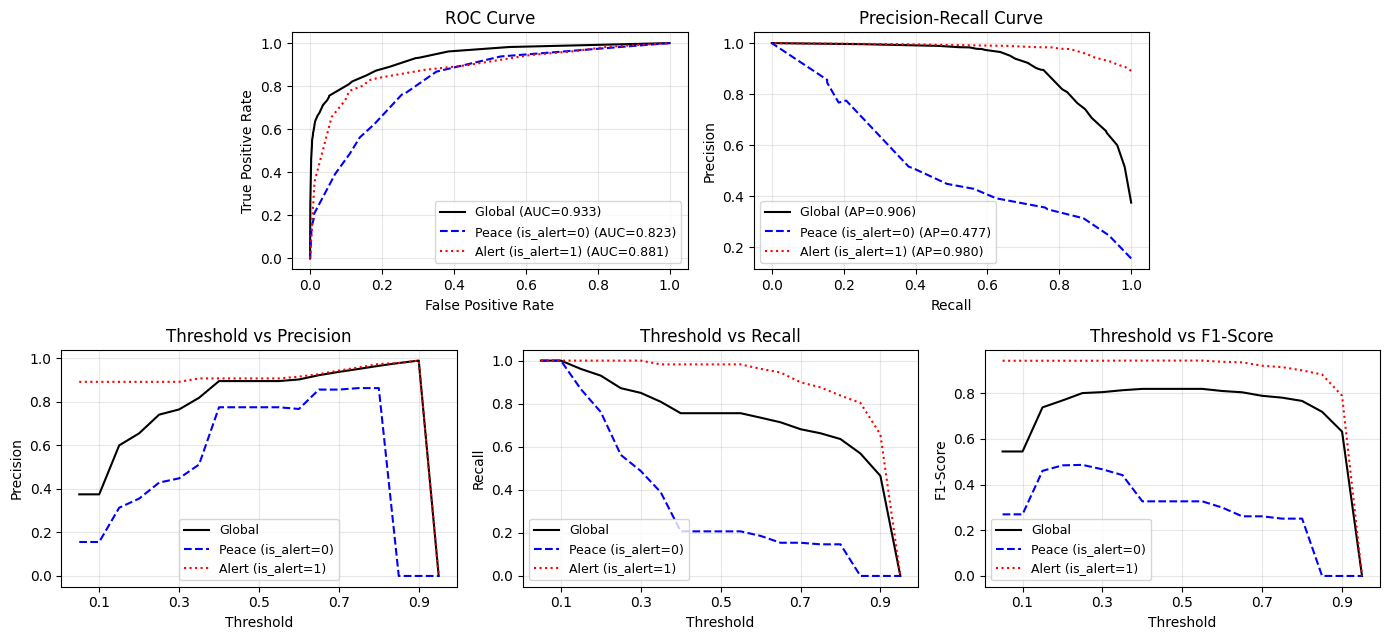


📊 Модель: Main LGBM
⏳ Час навчання: 9.70 сек
⏱ Час інференсу (на 35160 рядках): 0.1064 сек

📉 Log Loss:
   - Global: 0.2866
   - Peace (is_alert=0): 0.3136
   - Alert (is_alert=1): 0.2229

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,time_since_last_alert,1.538561e+06
1,neighbors_active_pct,3.436393e+05
2,current_duration_mins,1.470612e+05
3,alert_pct_24h,1.460143e+05
4,alert_pct_7d,1.361493e+05
5,oblast,9.314681e+04
6,alert_pct_30d,7.124345e+04
7,hour_cos,4.769847e+04
8,hour_sin,4.552687e+04
9,ua_active_pct,4.259524e+04


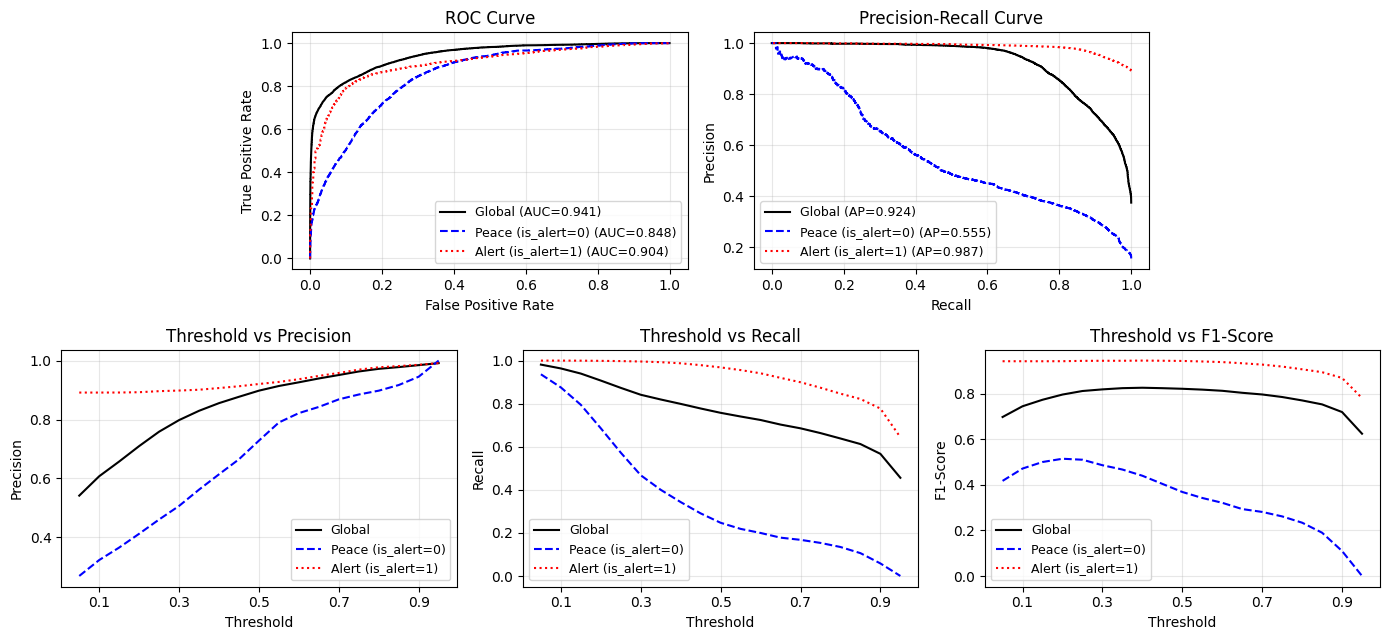


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [5]:
models1_60m, metrics1_60m = run_experiment(
    df_grid=grids1['60m'], 
    grid_name="60 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 30 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2024-07-01 00:00:00  -->  2026-09-07 06:30:00
Train:         2024-07-31 00:00:00  -->  2026-05-07 02:30:00
Gap 1:         2 години
Validation:    2026-05-07 04:30:00  -->  2026-07-07 04:30:00
Gap 2:         2 години
Test:          2026-07-07 06:30:00  -->  2026-09-07 06:30:00

Розміри вибірок:
Train: 743184 рядків
Val:   70296 рядків
Test:  71448 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 0.6479 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35136 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35136 рядках): 0.0006 сек

📉 Log Loss:
   - Global: 5.1169
   - Peace (is_alert=0): 5.6268
   - Alert (is_alert=1): 3.9129


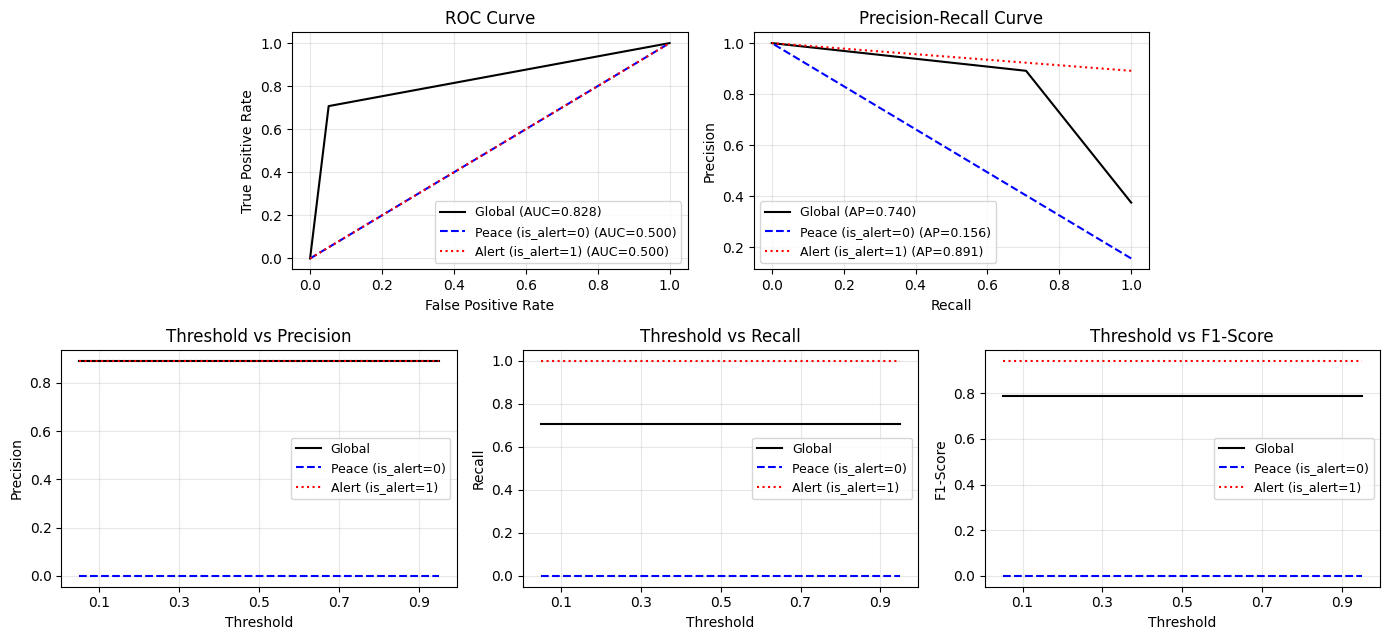


📊 Модель: Tree (1-step)
⏳ Час навчання: 0.65 сек
⏱ Час інференсу (на 35136 рядках): 0.0137 сек

📉 Log Loss:
   - Global: 0.3279
   - Peace (is_alert=0): 0.3505
   - Alert (is_alert=1): 0.2745


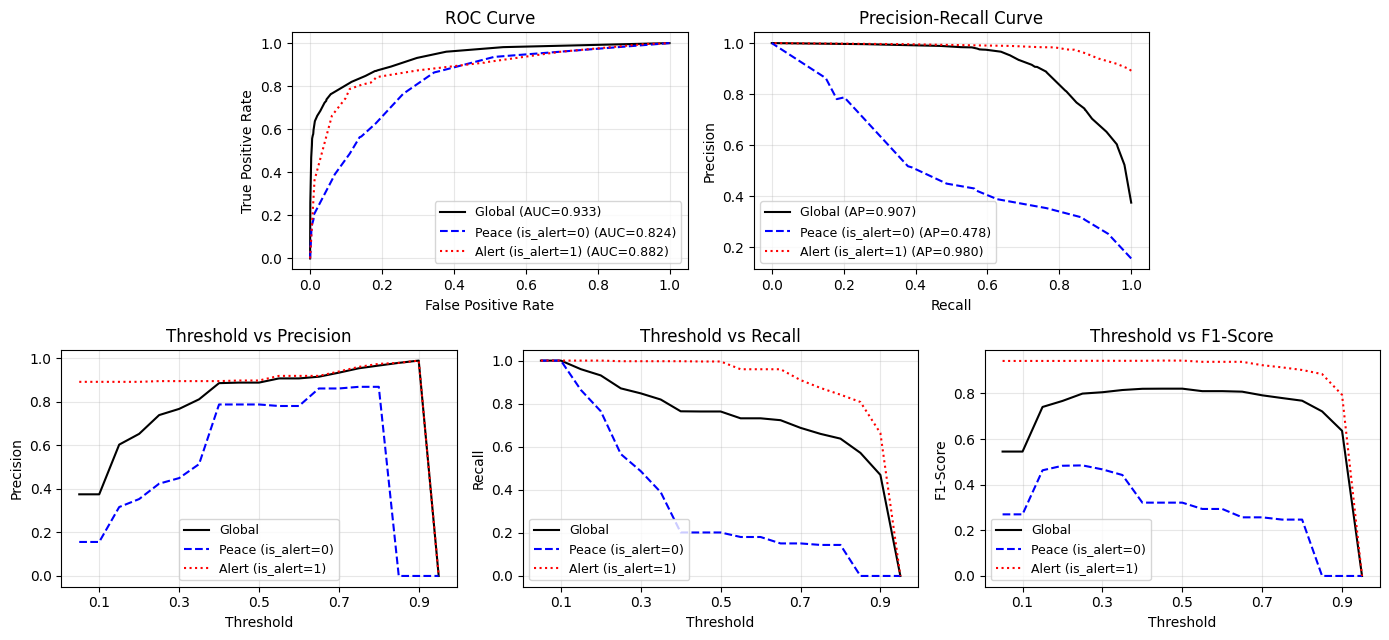


📊 Модель: Main LGBM
⏳ Час навчання: 10.06 сек
⏱ Час інференсу (на 35136 рядках): 0.1057 сек

📉 Log Loss:
   - Global: 0.2869
   - Peace (is_alert=0): 0.3137
   - Alert (is_alert=1): 0.2236

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,is_alert,1.781918e+06
1,time_since_last_alert,1.441329e+06
2,neighbors_active_pct,6.838336e+05
3,alert_pct_24h,2.840070e+05
4,alert_pct_7d,2.700592e+05
5,oblast,1.864954e+05
6,current_duration_mins,1.547257e+05
7,alert_pct_30d,1.436366e+05
8,hour_cos,8.987738e+04
9,hour_sin,8.644371e+04


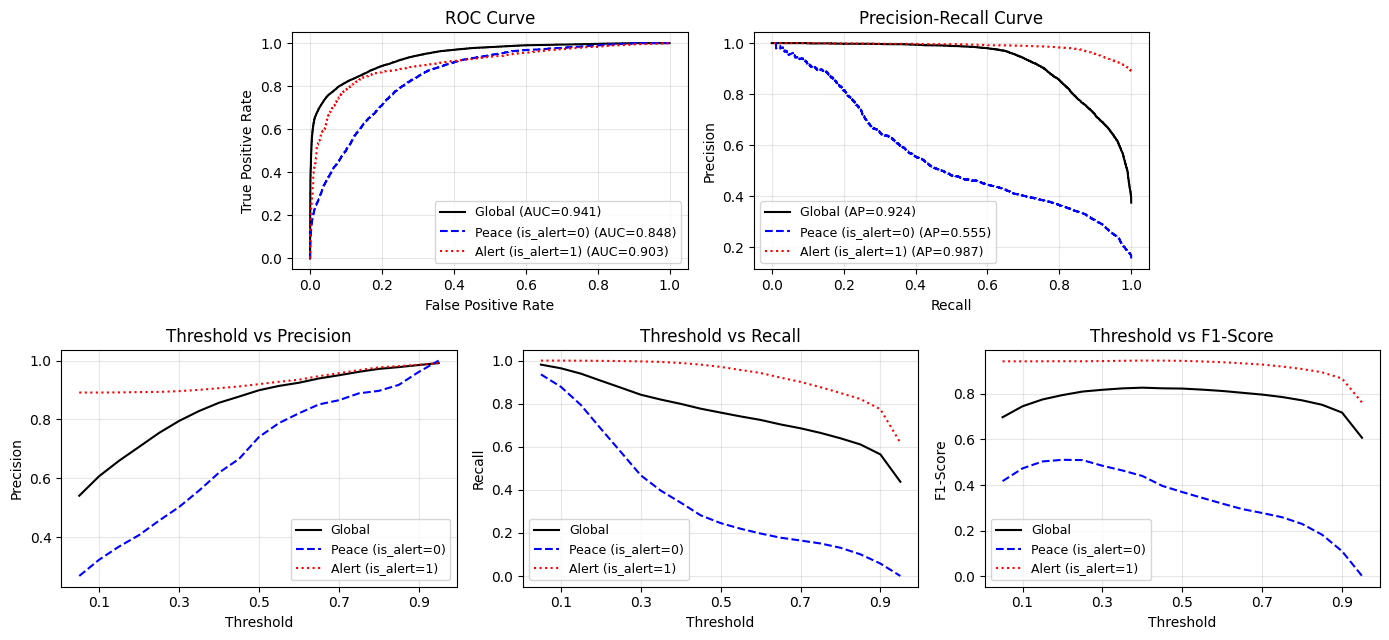


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [6]:
models1_30m, metrics1_30m = run_experiment(
    df_grid=grids1['30m'], 
    grid_name="30 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 15 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2024-07-01 00:00:00  -->  2026-09-07 06:30:00
Train:         2024-07-31 00:00:00  -->  2026-05-07 02:30:00
Gap 1:         2 години
Validation:    2026-05-07 04:30:00  -->  2026-07-07 04:30:00
Gap 2:         2 години
Test:          2026-07-07 06:30:00  -->  2026-09-07 06:30:00

Розміри вибірок:
Train: 1486344 рядків
Val:   140568 рядків
Test:  142872 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 1.4365 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35136 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35136 рядках): 0.0008 сек

📉 Log Loss:
   - Global: 5.1169
   - Peace (is_alert=0): 5.6268
   - Alert (is_alert=1): 3.9129


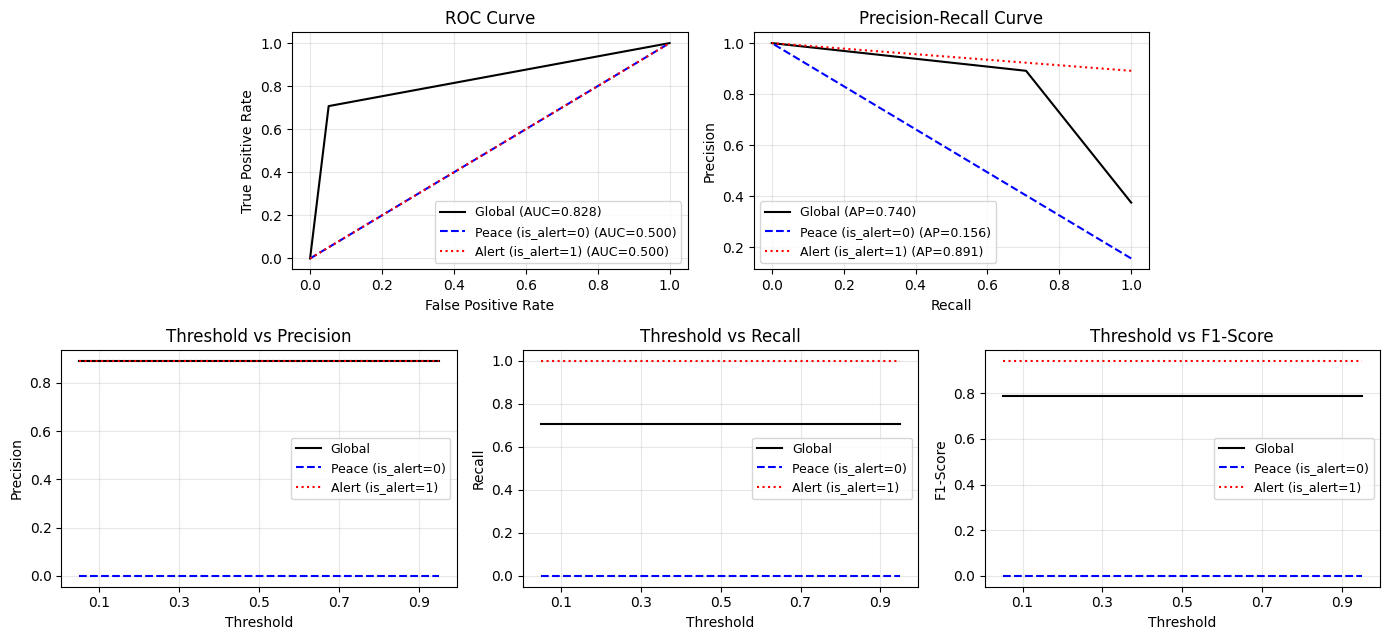


📊 Модель: Tree (1-step)
⏳ Час навчання: 1.44 сек
⏱ Час інференсу (на 35136 рядках): 0.0217 сек

📉 Log Loss:
   - Global: 0.3276
   - Peace (is_alert=0): 0.3499
   - Alert (is_alert=1): 0.2749


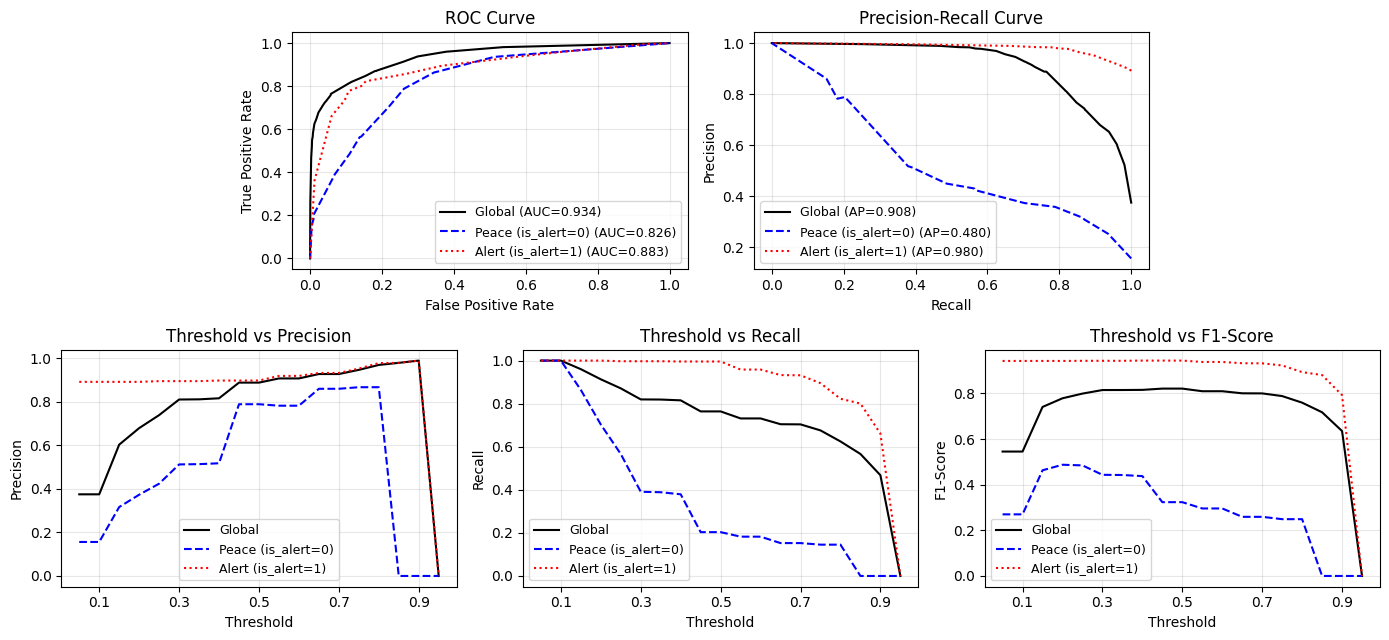


📊 Модель: Main LGBM
⏳ Час навчання: 20.54 сек
⏱ Час інференсу (на 35136 рядках): 0.1557 сек

📉 Log Loss:
   - Global: 0.2868
   - Peace (is_alert=0): 0.3139
   - Alert (is_alert=1): 0.2229

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,is_alert,6.594844e+06
1,neighbors_active_pct,1.364714e+06
2,alert_pct_24h,5.814493e+05
3,alert_pct_7d,5.580703e+05
4,oblast,3.892221e+05
5,alert_pct_30d,2.766362e+05
6,hour_cos,1.835048e+05
7,hour_sin,1.814898e+05
8,ua_active_pct,1.620849e+05
9,current_duration_mins,1.085324e+05


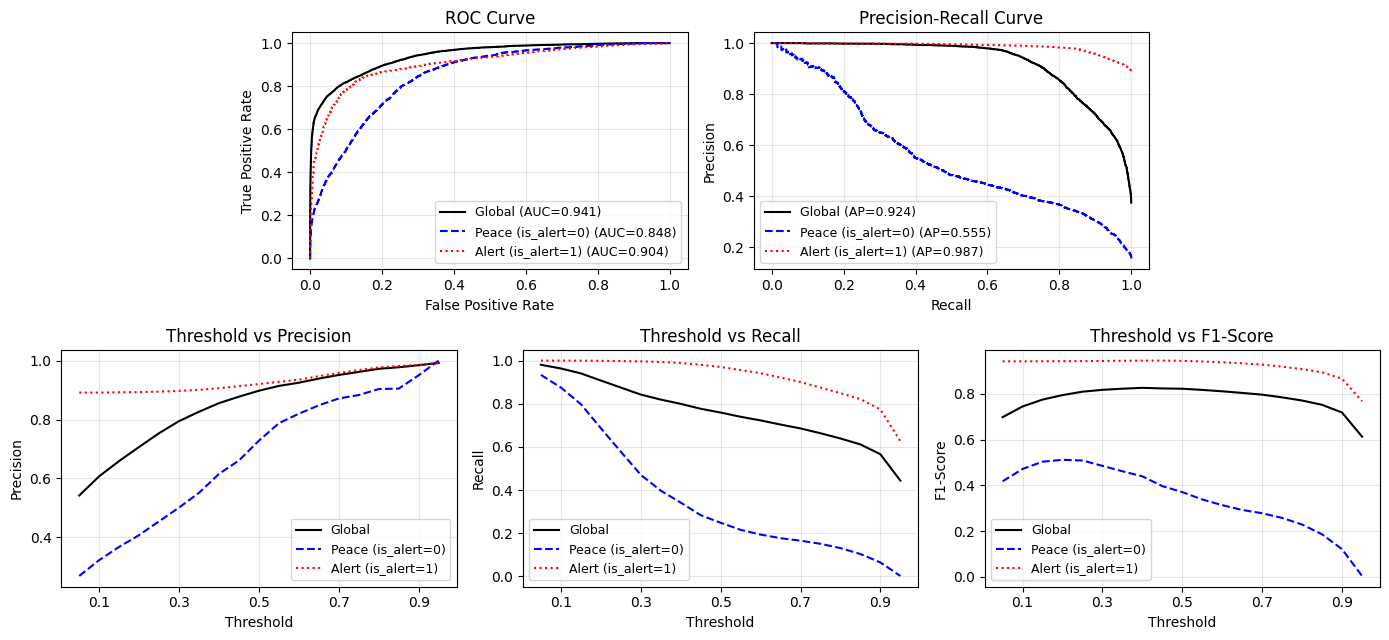


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [7]:
models1_15m, metrics1_15m = run_experiment(
    df_grid=grids1['15m'], 
    grid_name="15 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)

**Аналіз моделей**

Бачимо, що щільність навчальної вибірки, у тому форматі який ми задали майже не впливає на метрики якості у порівняних моделях. Практичний висновок: для наступних експериментів братимемо саме модель з кроком сітки 60 хв. Це в 4 рази менше рядків і ті самі метрики.

Далі у аналізі ми розглядатимемо саме модель з кроком сітки 60 хв. Серед трьох моделей найоптимальнішою є модель Main LGBM. Вона показує кращі результати за показником Avarage Precision: yаївний бейзлайн на Peace дає 0.156, що є просто частка позитивів, бустинг дає 0.555, тобто в 3,5 раза більше (важливо звернути увагу, що на наївній моделі для класу Peace він не дорівнює PR AUC у такому зображенні рисунку). Також порівнявши метрики на confusion matrix та classification Report, ми робимо рішення на користь цієї моделі саме через порівняння метрик на двох підзадачах, на глобальній вони мають приблизно однакові показники. Метрика LogLoss теж є нижчою.


**Запуск моделей з коротшим часом історії**


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 60 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2025-07-01 00:00:00  -->  2026-09-07 06:00:00
Train:         2025-07-31 00:00:00  -->  2026-05-07 02:00:00
Gap 1:         2 години
Validation:    2026-05-07 04:00:00  -->  2026-07-07 04:00:00
Gap 2:         2 години
Test:          2026-07-07 06:00:00  -->  2026-09-07 06:00:00

Розміри вибірок:
Train: 161352 рядків
Val:   35160 рядків
Test:  35736 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 0.2688 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35160 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35160 рядках): 0.0007 сек

📉 Log Loss:
   - Global: 5.1134
   - Peace (is_alert=0): 5.6225
   - Alert (is_alert=1): 3.9110


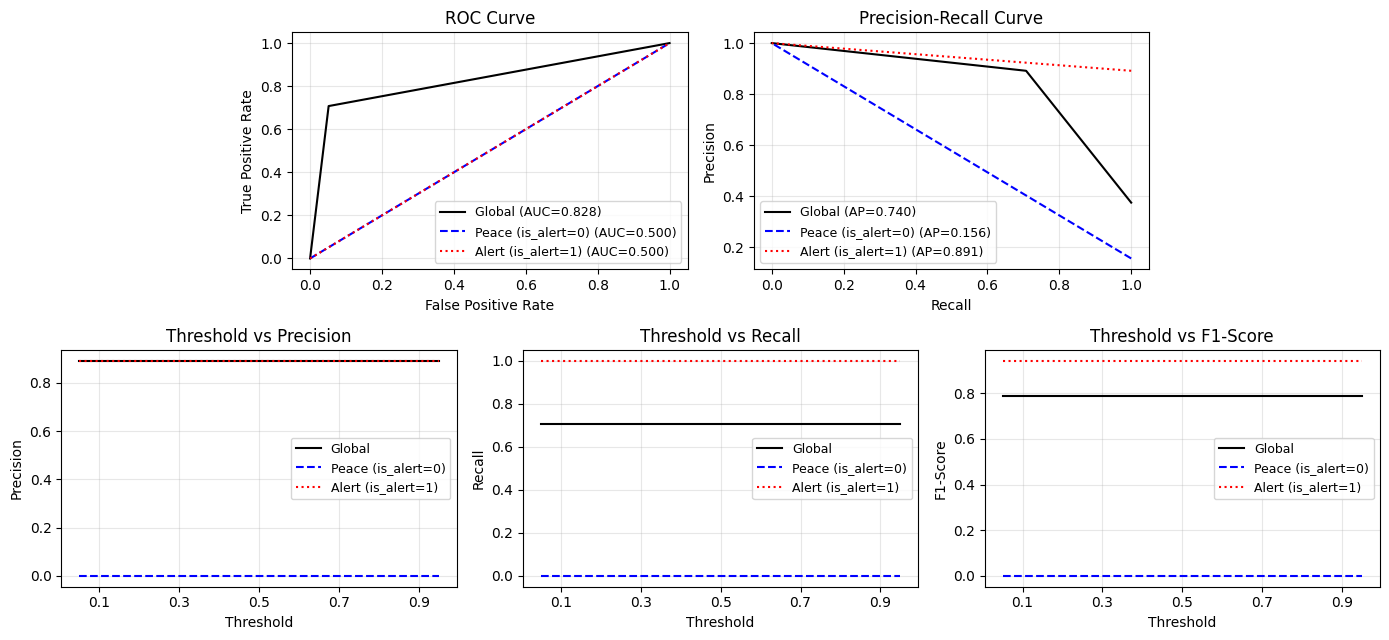


📊 Модель: Tree (1-step)
⏳ Час навчання: 0.27 сек
⏱ Час інференсу (на 35160 рядках): 0.0413 сек

📉 Log Loss:
   - Global: 0.3285
   - Peace (is_alert=0): 0.3524
   - Alert (is_alert=1): 0.2719


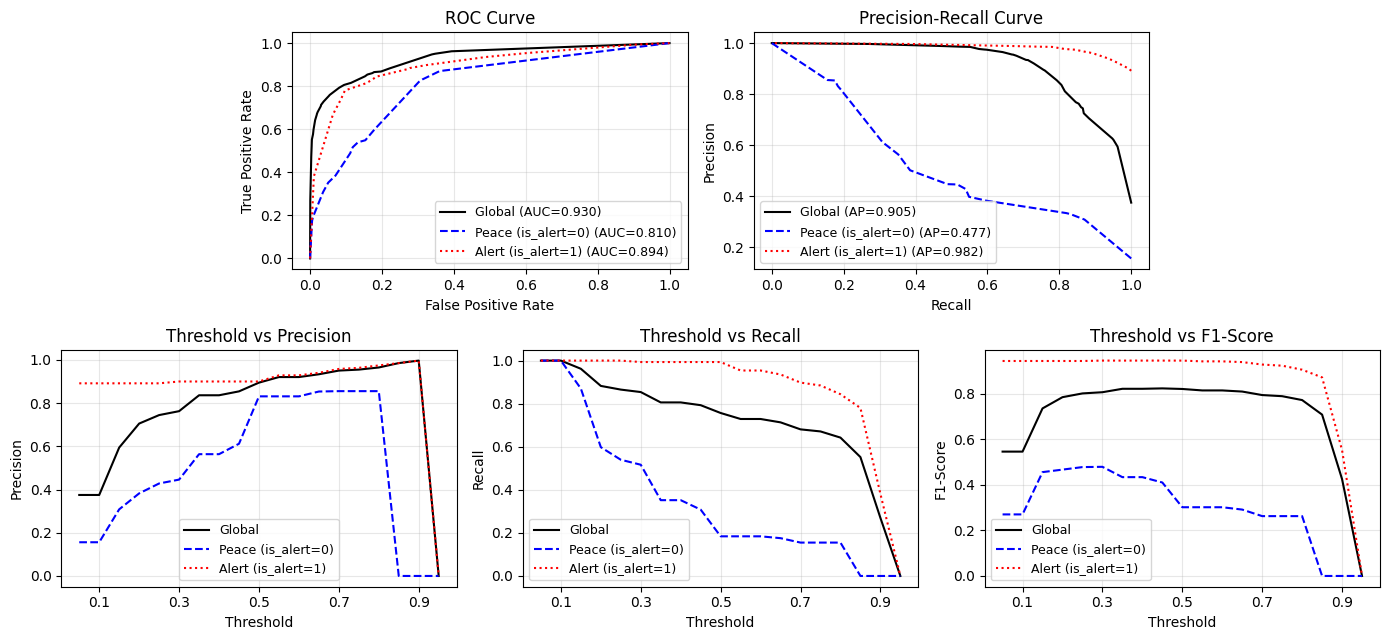


📊 Модель: Main LGBM
⏳ Час навчання: 2.16 сек
⏱ Час інференсу (на 35160 рядках): 0.2295 сек

📉 Log Loss:
   - Global: 0.2869
   - Peace (is_alert=0): 0.3136
   - Alert (is_alert=1): 0.2239

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,time_since_last_alert,735989.288736
1,neighbors_active_pct,119098.958688
2,alert_pct_24h,118656.194047
3,alert_pct_7d,80589.861852
4,oblast,51592.404563
5,alert_pct_30d,47654.423596
6,ua_active_pct,26236.373063
7,current_duration_mins,15237.140614
8,hour_sin,13318.678728
9,hour_cos,10316.691267


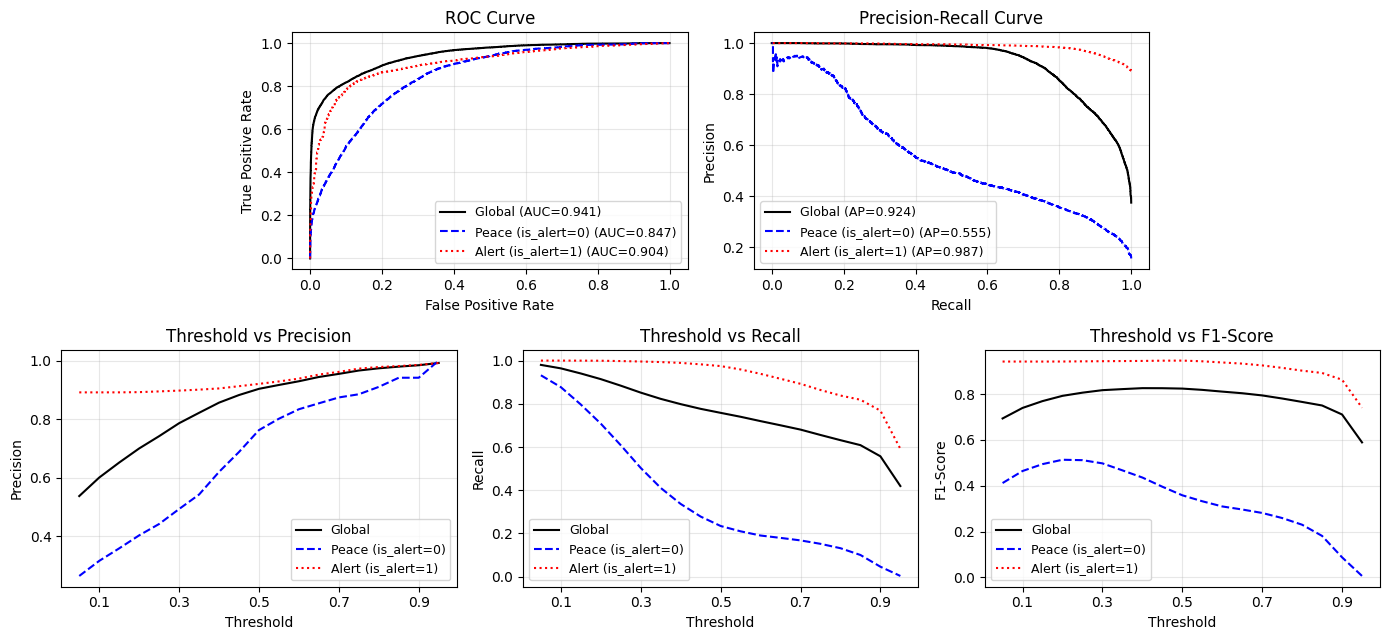


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [8]:
models2_60m, metrics2_60m = run_experiment(
    df_grid=grids2['60m'], 
    grid_name="60 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 30 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2025-07-01 00:00:00  -->  2026-09-07 06:30:00
Train:         2025-07-31 00:00:00  -->  2026-05-07 02:30:00
Gap 1:         2 години
Validation:    2026-05-07 04:30:00  -->  2026-07-07 04:30:00
Gap 2:         2 години
Test:          2026-07-07 06:30:00  -->  2026-09-07 06:30:00

Розміри вибірок:
Train: 322704 рядків
Val:   70296 рядків
Test:  71448 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 0.5472 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35136 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35136 рядках): 0.0006 сек

📉 Log Loss:
   - Global: 5.1169
   - Peace (is_alert=0): 5.6268
   - Alert (is_alert=1): 3.9129


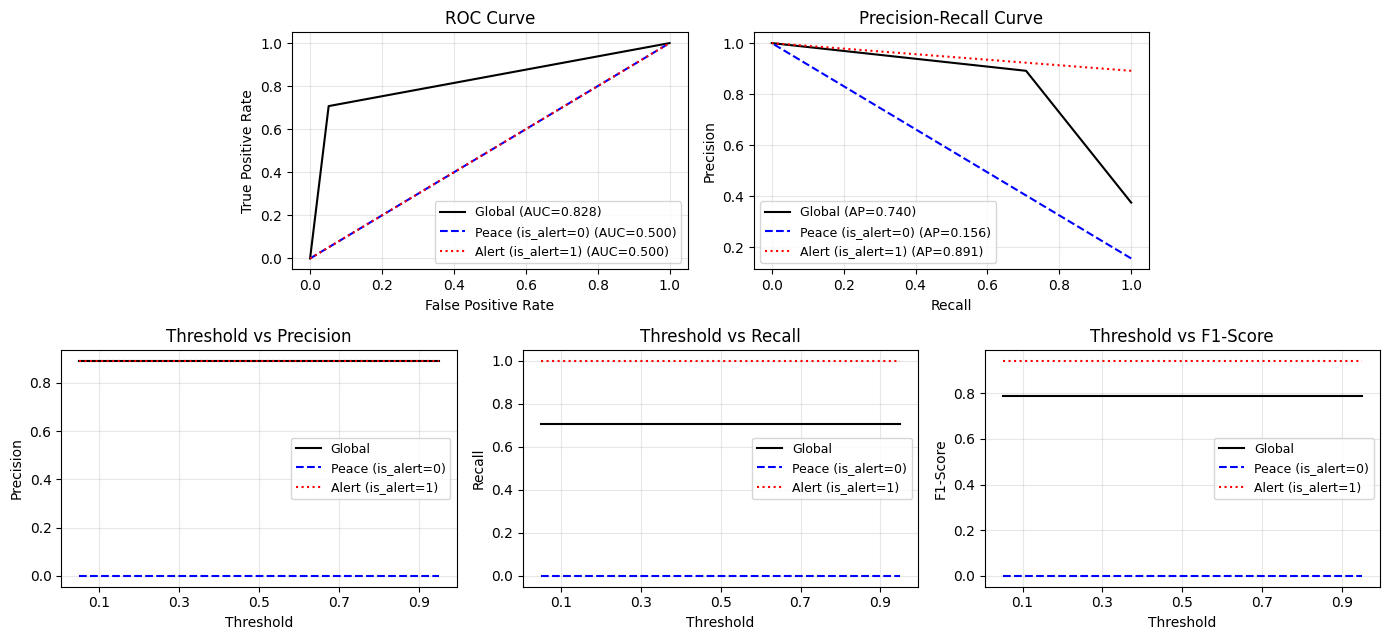


📊 Модель: Tree (1-step)
⏳ Час навчання: 0.55 сек
⏱ Час інференсу (на 35136 рядках): 0.0164 сек

📉 Log Loss:
   - Global: 0.3282
   - Peace (is_alert=0): 0.3514
   - Alert (is_alert=1): 0.2734


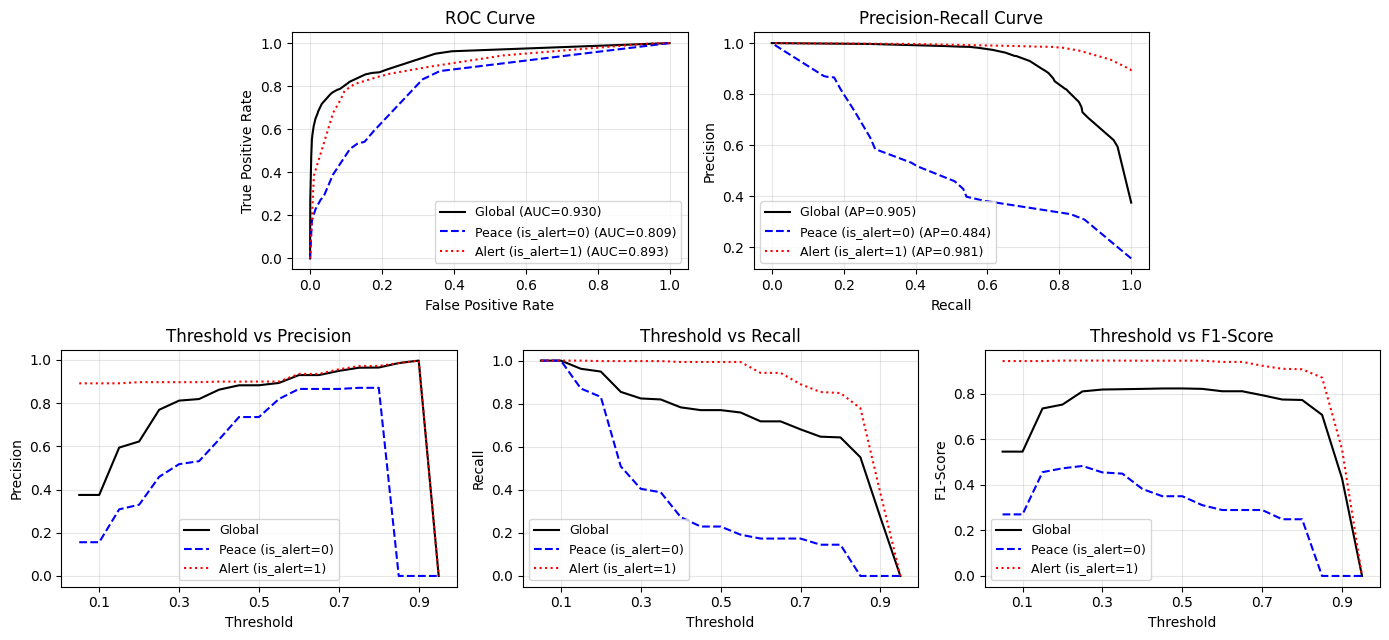


📊 Модель: Main LGBM
⏳ Час навчання: 5.58 сек
⏱ Час інференсу (на 35136 рядках): 0.1586 сек

📉 Log Loss:
   - Global: 0.2869
   - Peace (is_alert=0): 0.3142
   - Alert (is_alert=1): 0.2225

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,time_since_last_alert,1.357965e+06
1,neighbors_active_pct,2.391196e+05
2,alert_pct_24h,2.157954e+05
3,alert_pct_7d,1.614600e+05
4,is_alert,1.468518e+05
5,alert_pct_30d,1.121058e+05
6,oblast,1.063138e+05
7,ua_active_pct,5.272133e+04
8,hour_sin,3.181767e+04
9,hour_cos,2.552892e+04


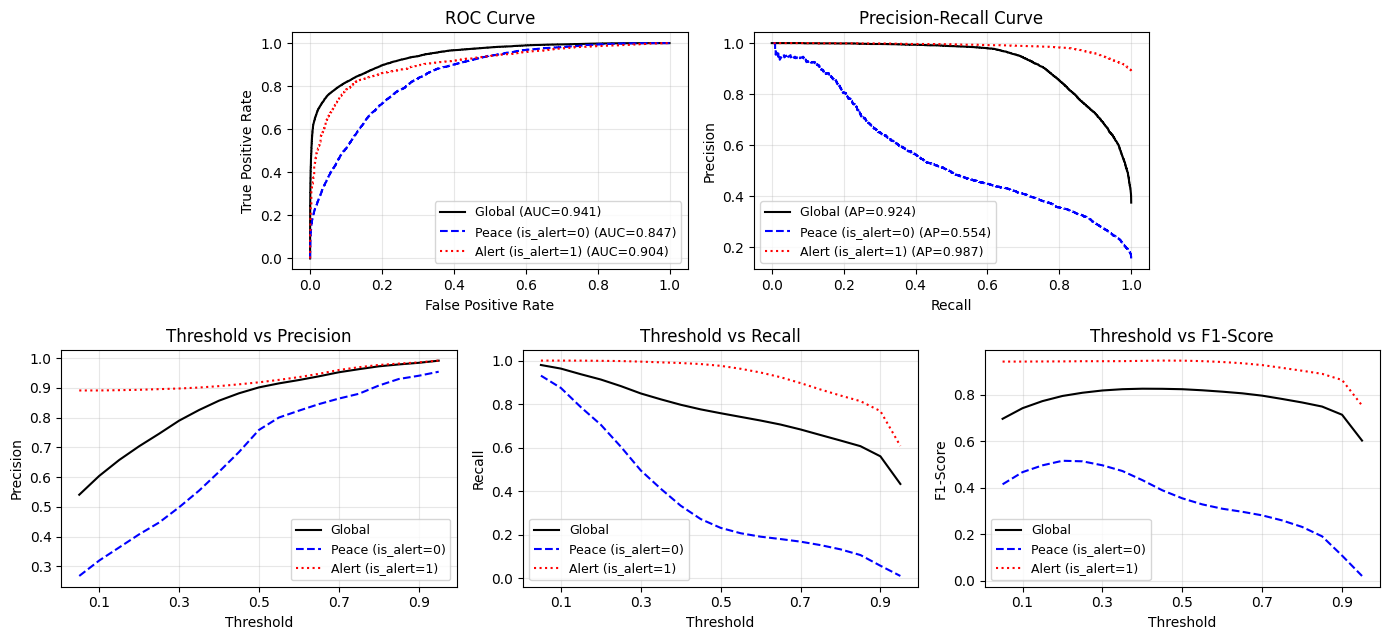


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [9]:
models2_30m, metrics2_30m = run_experiment(
    df_grid=grids2['30m'], 
    grid_name="30 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)


🚀 ЗАПУСК ЕКСПЕРИМЕНТУ: Сітка 15 хв (Scen 1)
--- Time-Series Split ---
Повний період: 2025-07-01 00:00:00  -->  2026-09-07 06:30:00
Train:         2025-07-31 00:00:00  -->  2026-05-07 02:30:00
Gap 1:         2 години
Validation:    2026-05-07 04:30:00  -->  2026-07-07 04:30:00
Gap 2:         2 години
Test:          2026-07-07 06:30:00  -->  2026-09-07 06:30:00

Розміри вибірок:
Train: 645384 рядків
Val:   140568 рядків
Test:  142872 рядків

--- НАВЧАННЯ ---
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.
[TreeBaseline] Навчання 1 дерева (max_depth=5) завершено за 0.8975 сек.


c:\Users\slipko\miniconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



--- ОЦІНКА НА ВАЛІДАЦІЇ (Common Nodes: хвилина 00) ---
Розмір валідації для оцінки (тільки xx:00): 35136 рядків

📊 Модель: Naive Baseline
⏳ Час навчання: 0.00 сек
⏱ Час інференсу (на 35136 рядках): 0.0005 сек

📉 Log Loss:
   - Global: 5.1169
   - Peace (is_alert=0): 5.6268
   - Alert (is_alert=1): 3.9129


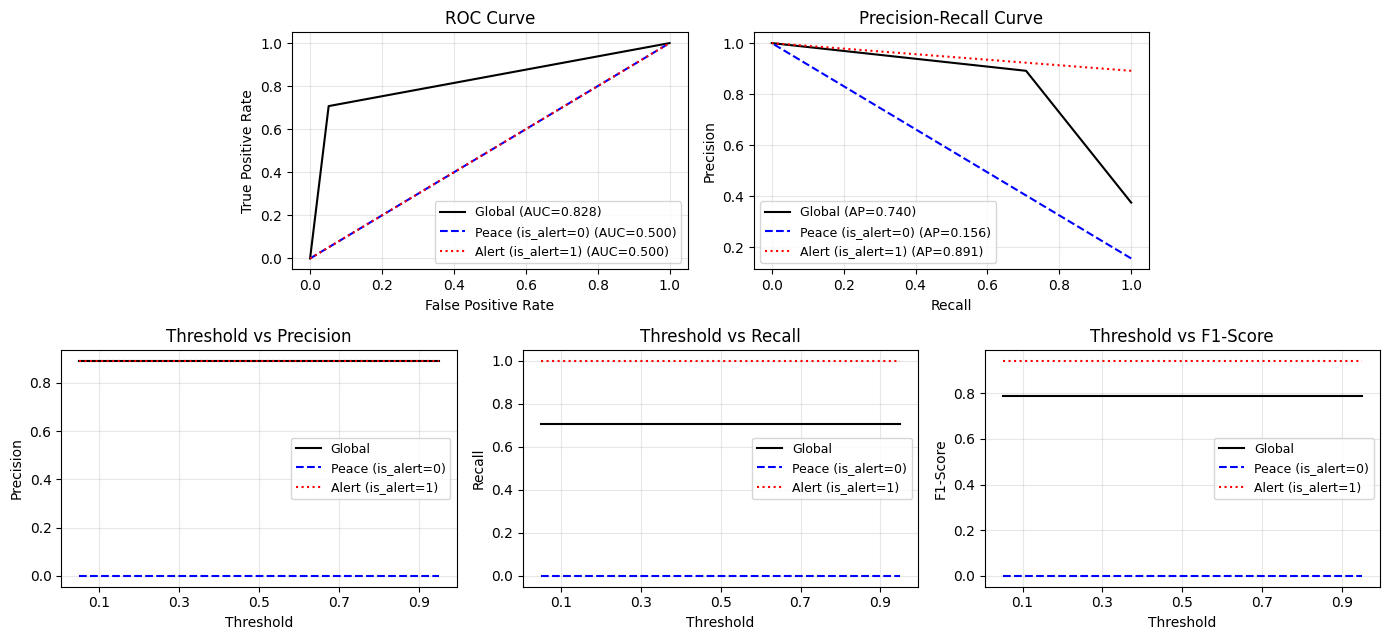


📊 Модель: Tree (1-step)
⏳ Час навчання: 0.90 сек
⏱ Час інференсу (на 35136 рядках): 0.0139 сек

📉 Log Loss:
   - Global: 0.3280
   - Peace (is_alert=0): 0.3511
   - Alert (is_alert=1): 0.2737


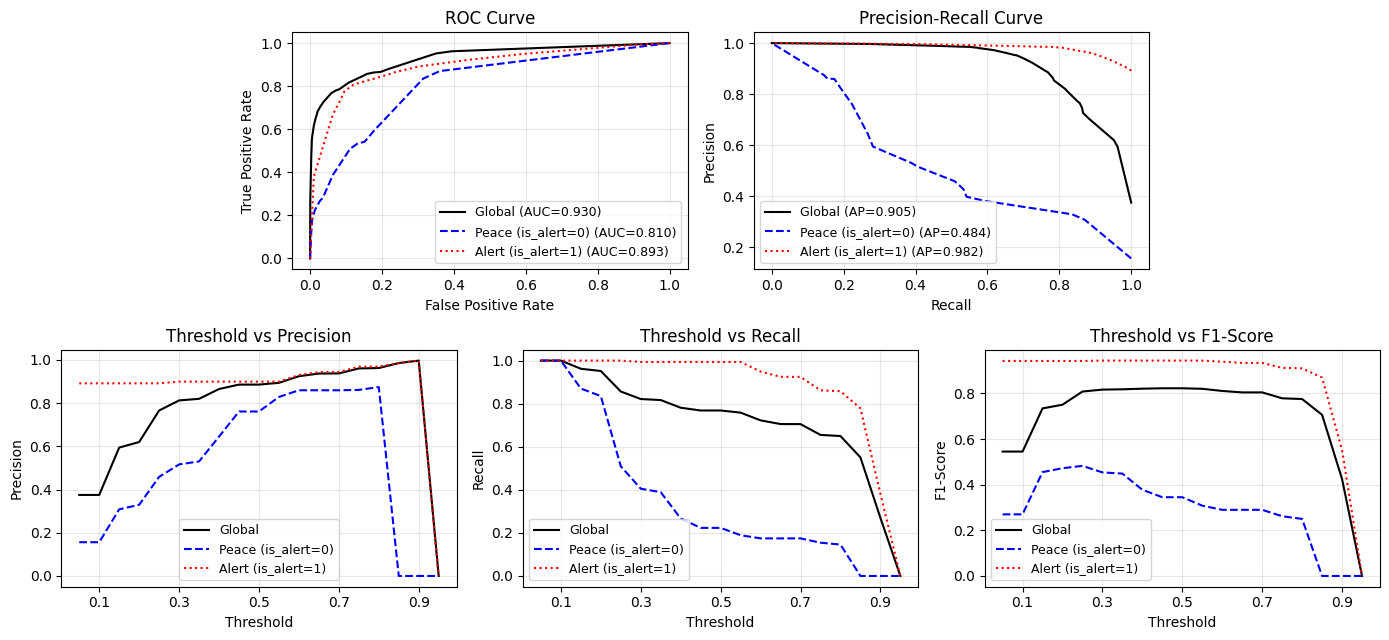


📊 Модель: Main LGBM
⏳ Час навчання: 7.85 сек
⏱ Час інференсу (на 35136 рядках): 0.0832 сек

📉 Log Loss:
   - Global: 0.2864
   - Peace (is_alert=0): 0.3133
   - Alert (is_alert=1): 0.2229

Топ-10 найважливіших ознак (Gain):


,Feature,Importance
0,is_alert,2.010085e+06
1,time_since_last_alert,9.912856e+05
2,neighbors_active_pct,4.810343e+05
3,alert_pct_24h,4.216189e+05
4,alert_pct_7d,3.397255e+05
5,oblast,2.142474e+05
6,alert_pct_30d,1.997016e+05
7,ua_active_pct,9.628972e+04
8,hour_sin,5.387802e+04
9,current_duration_mins,4.376239e+04


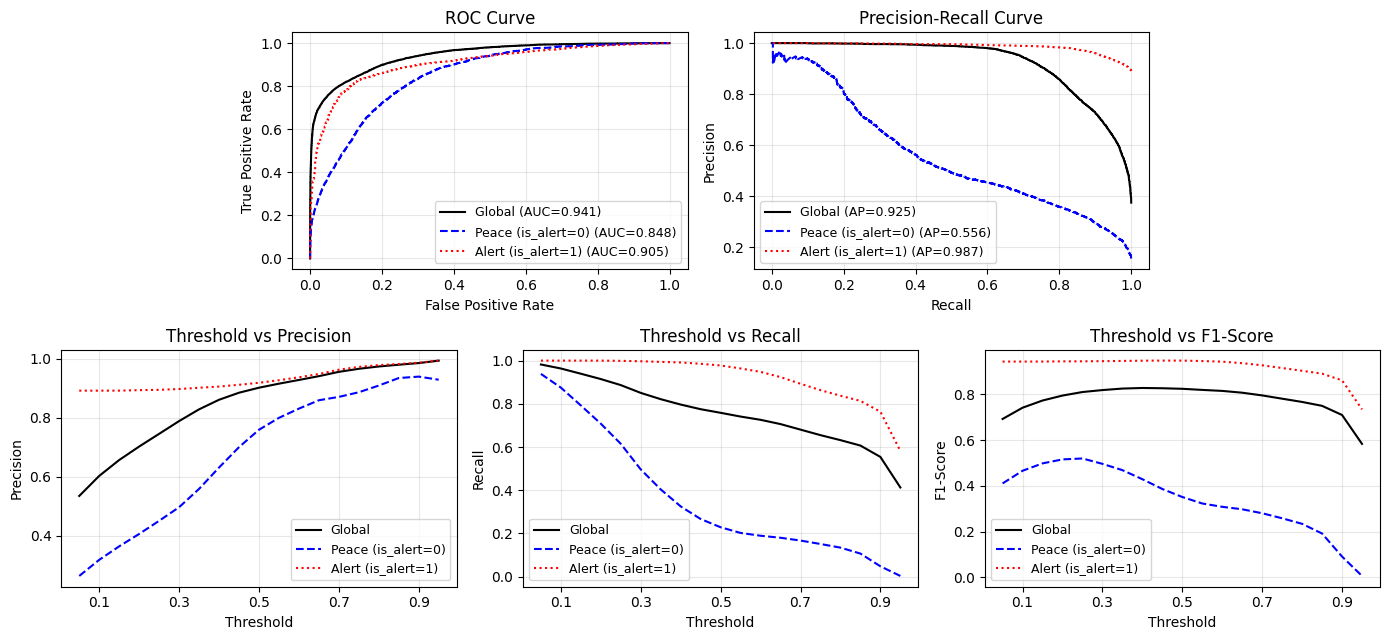


ПОРІВНЯЛЬНИЙ ЗВІТ (Threshold = 0.5)


In [10]:
models2_15m, metrics2_15m = run_experiment(
    df_grid=grids2['15m'], 
    grid_name="15 хв (Scen 1)", 
    lgbm_params={'n_estimators': 300, 'learning_rate': 0.05}
)

**Аналіз моделей**

Бачимо, що щільність навчальної вибірки, у тому форматі який ми задали тут також майже не впливає на метрики якості у порівняних моделях. Практичний висновок: для наступних експериментів братимемо саме модель з кроком сітки 60 хв.

Далі у аналізі ми розглядатимемо саме модель з кроком сітки 60 хв. За налогічною логіко з попереднього аналізу ми визначаємо, що серед трьох моделей найоптимальнішою є модель MainLGBM.

Наступним кроком є **порівняння двох моделей з різною довжиною історії**. Бачимо, що різниця між метриками мінімальна, а в деяких випадках прямо перемагає модель з коротшим часом. Менше хибних спрацювань, що робить її трохи надійнішою, трохи вища агрегована оцінка, кращі показники метрик для підкласів.

Графіки моделі MainLGBM на короткій історії показують, що для різних станів системи дійсно є сенс підбирати індивідуальні пороги. Але оскільки зараз у нас немає конкретної бізнес-задачі та розуміння ціни помилки, ми не будемо штучно зміщувати баланс. Тому поки що ми залишимо стандартний поріг для всіх підзадач на рівні 0.5.

**Тест**

In [12]:
df_train, df_val, df_test_60m = time_series_split(
    df=grids2['60m'],
    val_months=2, 
    test_months=2, 
    gap_hours=2, 
    burn_in_days=30
)

--- Time-Series Split ---
Повний період: 2025-07-01 00:00:00  -->  2026-09-07 06:00:00
Train:         2025-07-31 00:00:00  -->  2026-05-07 02:00:00
Gap 1:         2 години
Validation:    2026-05-07 04:00:00  -->  2026-07-07 04:00:00
Gap 2:         2 години
Test:          2026-07-07 06:00:00  -->  2026-09-07 06:00:00

Розміри вибірок:
Train: 161352 рядків
Val:   35160 рядків
Test:  35736 рядків


In [13]:
# 1. Об'єднуємо Train та Val
df_train_full = pd.concat([df_train, df_val], axis=0).sort_values('timestamp')

# === ФІКС PANDAS CONCAT ===
# Перетворюємо всі текстові колонки (object) назад у category для LightGBM
for col in df_train_full.select_dtypes(include=['object']).columns:
    df_train_full[col] = df_train_full[col].astype('category')
# ==========================

target_col = 'target_60_120m'
y_train_full = df_train_full[target_col]

print(f"Розмір старого Train: {len(df_train)}")
print(f"Розмір Train + Val (Full): {len(df_train_full)}")

# 2. Дістаємо оптимальну кількість дерев з нашої валідаційної моделі
best_iters = models2_60m["Main LGBM"].model.best_iteration_
print(f"Оптимальна кількість дерев (з валідації): {best_iters}")

# 3. Ініціалізуємо ФІНАЛЬНУ модель (early_stopping_rounds=None)
final_lgbm_params = {'n_estimators': best_iters, 'learning_rate': 0.05}
final_lgbm = MainLGBM(params=final_lgbm_params, early_stopping_rounds=None)

# 4. Перенавчаємо Main LGBM та Naive Baseline
print("\n🔄 Перенавчаємо Main LGBM на об'єднаних даних...")
final_lgbm.fit(df_train_full, y_train_full)

print("🔄 Готуємо Naive Baseline...")
final_naive = NaiveBaseline()
final_naive.fit(df_train_full)

print("\n✅ Готово! Моделі перенавчені і готові до тесту.")

Розмір старого Train: 161352
Розмір Train + Val (Full): 196512
Оптимальна кількість дерев (з валідації): 103

🔄 Перенавчаємо Main LGBM на об'єднаних даних...
🔄 Готуємо Naive Baseline...
[NaiveBaseline] 'Навчання' завершено за 0.000000 сек.

✅ Готово! Моделі перенавчені і готові до тесту.


In [14]:
# 1. Оцінка Naive Baseline на тесті
print("\n" + "⭐"*40)
print("БЕЙЗЛАЙН: Naive Baseline")
print("⭐"*40)
evaluate_on_test(
    model=final_naive, 
    df_test=df_test_60m, # Твій тестовий датасет
    threshold=0.5
)

# 2. Оцінка фінального Main LGBM на тесті
print("\n" + "🔥"*40)
print("ФІНАЛЬНА МОДЕЛЬ: Main LGBM")
print("🔥"*40)
evaluate_on_test(
    model=final_lgbm, 
    df_test=df_test_60m, 
    threshold=0.5
)


⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐
БЕЙЗЛАЙН: Naive Baseline
⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐⭐

🚀 ОЦІНКА НА ТЕСТОВІЙ ВИБІРЦІ (Threshold = 0.5)
Розмір тестової вибірки для оцінки: 35736 рядків



🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥
ФІНАЛЬНА МОДЕЛЬ: Main LGBM
🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥🔥

🚀 ОЦІНКА НА ТЕСТОВІЙ ВИБІРЦІ (Threshold = 0.5)
Розмір тестової вибірки для оцінки: 35736 рядків


Справді, наша модель справляється краще за наївну.

⏳ Рахуємо SHAP-значення (це може зайняти хвилину)...


c:\Users\slipko\miniconda3\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


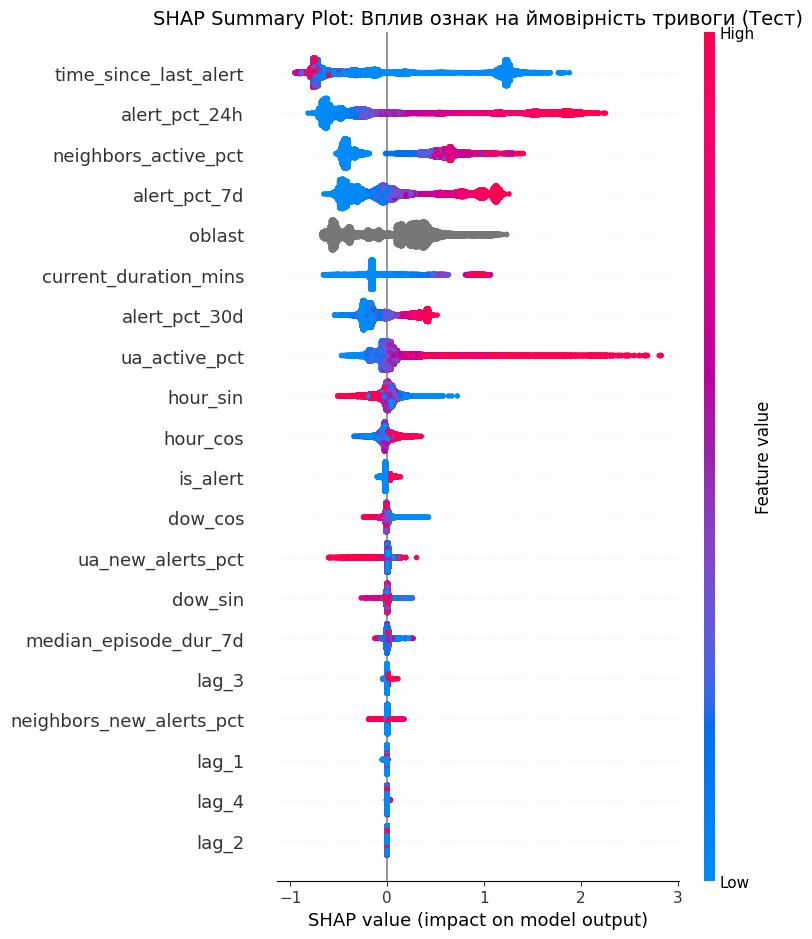

In [15]:
plot_shap_summary(
    model=final_lgbm, 
    df_test=df_test_60m, 
    df_train=df_train_full, 
    max_display=20
)

Цікаво побачити, стан тривоги на даний момент було не однією з головних ознак.